# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.


## Where this lab fits in our project

**Project.** A *Climate Exposure & Mispricing Score* for listed companies in four hard-to-abate sectors (aviation, automotive, cement, shipping). Question: does the market already price carbon-transition risk, and how does company value move when the climate scenario changes?

**Two stages.**
1. **Exposure (Stage 1).** Simulate the carbon bill and its effect on EBITDA under scenarios, with a range instead of one number.
2. **Pricing (Stage 2).** Regress observed EV/EBITDA on that exposure, with controls (leverage, growth, sector, region). The residuals rank companies for a theoretical long/short.

**This lab is Stage 1, at sector level.** Its key quantity is the EU ETS carbon cost of aviation + cement (EU totals). It gives us (i) the range of the carbon bill, (ii) the input that drives it, and (iii) the price scenarios we will reuse company by company.

**Not in this lab, on purpose.**
* Company-level costs and the link to EBITDA need company emissions and Bloomberg data (optional bridge in D2, empty until we have them).
* The regression on valuation multiples is Stage 2, for the final paper.
* Automotive has no carbon price (it pays a fleet-target penalty) and shipping has only been in the ETS since 2024, too short for a back-test.

**What carries forward to the final project.** The carbon-price distribution and scenarios, the cement free-allocation schedule, and the back-test lesson that a linear trend fails on this series.


## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Oscar Moulet  Student ID: B00821262
2. Full name: Adrien Labergere  Student ID: B00822082
3. Full name: Lucas Magret Delord  Student ID: B00819377
4. Full name: Louis Bettelli  Student ID: B00820941

**Project role (consultant / data scientist / risk analyst):** Risk analyst (Climate Risk Analyst, finance / quant)
**Key quantity (one sentence, with unit):** The annual gross EU ETS carbon cost of the aviation and cement sectors (EU verified emissions x average EU ETS auction price, before free allocation), in EUR bn per year; it is the sector-level input of Stage 1 (exposure) of our Climate Exposure & Mispricing Score.
**Repo URL:** https://github.com/Coachbet/moulet-labergere-magret_delord-bettelli

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = False   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # EU ETS auction price (ICAP Allowance Price Explorer, primary market, EUR/t): daily -> yearly mean
    icap = pd.read_csv("data/icap-graph-price-data-2005-01-01-2026-10-25.csv", header=1)
    daily = pd.DataFrame({
        "year": pd.to_datetime(icap["Date"]).dt.year,
        "price": icap.iloc[:, 4].fillna(icap.iloc[:, 9]),   # col 4: EU ETS until 2018, col 9: EU ETS from 2019
    }).dropna()
    price = daily[daily["year"] <= 2025].groupby("year")["price"].mean()   # 2026 is not complete yet

    # EU ETS verified emissions by sector (EEA, EU Transaction Log), MtCO2, kept separate per sector
    ets = pd.read_csv("data/eu-ets-sector-emissions.csv")
    ets = ets[ets["sector"].isin(["10 Aviation", "29 Production of cement clinker"])]
    em = (ets.pivot(index="year", columns="sector", values="emissions_mt")
             .rename(columns={"10 Aviation": "aviation_mt", "29 Production of cement clinker": "cement_mt"}))

    # We start in 2013. The 2012 aviation figure (84 Mt, against 53 Mt in 2013) most likely reflects a
    # different scope (the ETS was limited to intra-EEA flights from 2013): to be checked at the source.
    em = em[em.index >= 2013].dropna()
    em["emissions_mt"] = em["aviation_mt"] + em["cement_mt"]

    inputs = pd.concat([em, price.rename("price_eur")], axis=1).dropna()
    inputs.index = inputs.index.astype(int)
    series = pd.DataFrame({
        "year": inputs.index,
        "value": (inputs["emissions_mt"] * inputs["price_eur"] / 1000).to_numpy(),  # Mt x EUR/t = EUR m -> EUR bn
    })
    NAME, UNIT = "EU ETS gross carbon cost, aviation + cement", "EUR bn"
series.tail()

,year,value
8,2021,7.60
9,2022,12.38
10,2023,12.47
11,2024,9.89
12,2025,9.96


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our key quantity is the annual **gross** EU ETS carbon cost of the aviation and cement sectors: EU verified emissions (EEA) times the average EU ETS auction price (ICAP), in EUR bn per year over 2013-2025. "Gross" means every tonne is valued at the market price, before free allocation (see Q4 and Q6). In our project it is the sector-level input of Stage 1 (exposure): the decision that depends on it is how hard we stress each company's EBITDA before comparing it with its valuation multiples in Stage 2, and therefore which companies we flag as exposed. Its main sources of uncertainty are:

* **A** (aleatoric): the year-to-year volatility of the carbon price, and activity shocks such as COVID for aviation in 2020.
* **E** (epistemic): how fast aviation and cement emissions will move to 2030 (our paths are judgement calls), how much of the cost is really paid after free allocation, and whether the 2025 emissions are final.
* **S** (scenario): the policy path (MSR tightening, CBAM and the phase-out of free allocation, scope of the ETS for aviation).

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model, level=0.90):
    """Fit on `train` (columns year, value) and predict the next `horizon` years.
    Returns year, mean, lo, hi, where [lo, hi] is a prediction interval at `level`."""
    years = train["year"].to_numpy(dtype=float)
    y = train["value"].to_numpy(dtype=float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    elif model != "linear":
        raise ValueError("model must be 'linear' or 'loglinear'")

    n = len(y)
    x_mean = years.mean()
    X = np.column_stack([np.ones(n), years - x_mean])        # centred year
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    s2 = resid @ resid / (n - 2)                              # residual variance
    t_crit = stats.t.ppf(0.5 + level / 2, df=n - 2)

    future = years.max() + np.arange(1, horizon + 1)
    X0 = np.column_stack([np.ones(horizon), future - x_mean])
    mean = X0 @ beta
    leverage = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)      # x0' (X'X)^-1 x0
    half = t_crit * np.sqrt(s2 * (1 + leverage))              # prediction interval (not a CI)
    lo, hi = mean - half, mean + half
    if model == "loglinear":                                  # back to the original scale
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)   # (mean is then the median)
    return pd.DataFrame({"year": future.astype(int), "mean": mean, "lo": lo, "hi": hi})


H = 5                                                         # hold out the last 5 years
train, test = series.iloc[:-H], series.iloc[-H:]

parts = []
for m in ["linear", "loglinear"]:
    pred = fit_predict(train, H, m)
    pred["model"] = m
    parts.append(pred)

backtest = pd.concat(parts, ignore_index=True).merge(
    test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = (backtest["actual"] >= backtest["lo"]) & (backtest["actual"] <= backtest["hi"])
backtest[["model", "year", "actual", "mean", "lo", "hi", "inside"]]

,model,year,actual,mean,lo,hi,inside
0,linear,2021,7.60,4.28,2.12,6.45,False
1,linear,2022,12.38,4.79,2.47,7.10,False
2,linear,2023,12.47,5.29,2.80,7.78,False
3,linear,2024,9.89,5.79,3.11,8.47,False
4,linear,2025,9.96,6.29,3.41,9.17,False
5,loglinear,2021,7.60,4.97,2.03,12.19,True
6,loglinear,2022,12.38,6.37,2.44,16.67,True
7,loglinear,2023,12.47,8.17,2.91,22.96,True
8,loglinear,2024,9.89,10.48,3.45,31.83,True
9,loglinear,2025,9.96,13.43,4.07,44.34,True


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

In [4]:
# (a) held-out years inside the 90% band
hits = backtest.groupby("model")["inside"].sum()
print("Held-out years inside the 90% band (out of 5):")
print(hits.to_string())

# (b) if the band were really 90%, a miss happens with p = 0.1: P(X >= k) for X ~ Bin(5, 0.1)
k = np.arange(0, 6)
binom_tail = pd.DataFrame({"k misses": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.1)})
binom_tail["P(X >= k)"] = binom_tail["P(X >= k)"].map("{:.4f}".format)
binom_tail

Held-out years inside the 90% band (out of 5):
model
linear       0
loglinear    5


,k misses,P(X >= k)
0,0,1.0000
1,1,0.4095
2,2,0.0815
3,3,0.0086
4,4,0.0005
5,5,0.0000


**Your answer (Q2):**

**(a)** Trained on 2013-2020 (8 years), the linear model has **0 of 5** held-out years (2021-2025) inside its 90% band, and the log-linear model has **5 of 5**.

**(b)** If the band were really 90%, a miss has probability 0.1 per year: two misses give P(X >= 2) = 0.08 (already suspicious) and three give P(X >= 3) = 0.009 (I would clearly doubt the band). The linear model has 5 misses (P(X >= 5) = 0.00001), so its band is not calibrated, while the log-linear model has none, which is consistent with 90%.

**(c)** I keep the log-linear model, the only one whose band holds, but it holds mostly because it is very wide (4.1 to 44.3 EUR bn in 2025 around an actual 10.0) and its centre is off in both directions (8.2 vs 12.5 in 2023, 13.4 vs 10.0 in 2025). The rolling back-test agrees: the log-linear coverage is 100% / 75% / 100% at 1 / 2 / 3 years, against 60% / 50% / 67% for the linear model. The gap between the models comes from the price jump after the 2018 MSR reform and in 2021, a policy break that a trend fitted on 2013-2020 cannot see. So the choice of model is itself a large source of uncertainty, and I do not use the failed linear trend in Part F.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# Rolling origin: train on the first `end` years, predict 1 to 3 years ahead.
# The lab suggests starting at the 10th year; with 13 years of data (2013-2025) that leaves only 1-3 tests per
# horizon, so we start at 8 years of training data (2013-2020) to get 3-5 tests per horizon.
MIN_TRAIN = 8
rows = []
for end in range(MIN_TRAIN, len(series)):
    tr = series.iloc[:end]
    h_max = min(3, len(series) - end)               # only horizons for which the truth is known
    for m in ["linear", "loglinear"]:
        pred = fit_predict(tr, h_max, m)
        pred["model"] = m
        pred["horizon"] = pred["year"] - tr["year"].iloc[-1]
        rows.append(pred)

rolling = pd.concat(rows, ignore_index=True).merge(
    series.rename(columns={"value": "actual"}), on="year")
rolling["inside"] = (rolling["actual"] >= rolling["lo"]) & (rolling["actual"] <= rolling["hi"])

coverage = (rolling.groupby(["model", "horizon"])["inside"]
            .agg(coverage="mean", n_tests="count").reset_index())
coverage["coverage"] = 100 * coverage["coverage"]
coverage.rename(columns={"coverage": "coverage (%)"})

,model,horizon,coverage (%),n_tests
0,linear,1,60.00,5
1,linear,2,50.00,4
2,linear,3,66.67,3
3,loglinear,1,100.00,5
4,loglinear,2,75.00,4
5,loglinear,3,100.00,3


---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET_YEAR = 2030
H_C = TARGET_YEAR - inputs.index.max()          # 5 years after the last observed year (2025)


def compute_quantity(aviation_mt, cement_mt, price_eur, cement_paid_share=1.0):
    """Carbon cost (EUR bn) = (aviation + paid share of cement emissions, MtCO2) x EU ETS price (EUR/t) / 1000.
    With cement_paid_share = 1 this is the GROSS cost (every tonne at the market price)."""
    return (aviation_mt + cement_paid_share * cement_mt) * price_eur / 1000


# ---- Input 1: 2030 emissions, modelled sector by sector because the two sectors move in opposite directions.
# Triangular(low, mode, high): we do not know the pace, only a plausible range. These are judgement calls that
# we would replace with installation-level data.
# Aviation (rebound after COVID, offset by efficiency and SAF):
#   low = flat at the 2025 level, mode = back to the 2019 (pre-COVID) level, high = 10% above 2019.
av_2025, av_2019 = inputs["aviation_mt"].iloc[-1], inputs.loc[2019, "aviation_mt"]
av_low, av_mode, av_high = av_2025, av_2019, 1.10 * av_2019
aviation_2030 = rng.triangular(av_low, av_mode, av_high, N)

# Cement (declining since 2019):
#   low = the 2019-2025 pace continues, mode = half that pace (the 2022-2025 demand shock fades), high = flat.
ce_2025 = inputs["cement_mt"].iloc[-1]
g_ce = (ce_2025 / inputs.loc[2019, "cement_mt"]) ** (1 / 6) - 1
ce_low, ce_mode, ce_high = ce_2025 * (1 + g_ce) ** H_C, ce_2025 * (1 + g_ce / 2) ** H_C, ce_2025
cement_2030 = rng.triangular(ce_low, ce_mode, ce_high, N)

# ---- Input 2: 2030 EU ETS price ~ Lognormal: a price cannot be negative and its changes are multiplicative.
# Median = 2025 average price (random walk, no drift); sigma = st. dev. of the annual log changes since
# the 2018 MSR reform, scaled by sqrt(5) for a 5-year horizon.
p_2025 = inputs["price_eur"].iloc[-1]
sigma_year = np.diff(np.log(inputs.loc[2018:, "price_eur"])).std(ddof=1)
price_2030 = p_2025 * np.exp(rng.normal(0, sigma_year * np.sqrt(H_C), N))

print(f"Aviation 2030 ~ Triangular({av_low:.1f}, {av_mode:.1f}, {av_high:.1f}) MtCO2")
print(f"Cement 2030   ~ Triangular({ce_low:.1f}, {ce_mode:.1f}, {ce_high:.1f}) MtCO2  (2019-2025 pace: {g_ce:.1%}/yr)")
print(f"Price 2030    ~ Lognormal(median {p_2025:.1f} EUR/t, sigma {sigma_year * np.sqrt(H_C):.2f})  (annual sigma {sigma_year:.2f})")

draws = compute_quantity(aviation_2030, cement_2030, price_2030)
q05, q50, q95 = np.percentile(draws, [5, 50, 95])
print(f"{TARGET_YEAR} {NAME}: median = {q50:,.1f} {UNIT}, 90% interval = [{q05:,.1f}, {q95:,.1f}] {UNIT}")


# One-at-a-time sensitivity: fix one input at its median, keep the other random
def summarise(x):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    return med, lo, hi, 100 * (hi - lo) / 2 / med      # relative half-width in %


av_med, ce_med = np.median(aviation_2030), np.median(cement_2030)
cases = {
    "Both inputs random": draws,
    "Emissions fixed at their median": compute_quantity(av_med, ce_med, price_2030),
    "Price fixed at its median": compute_quantity(aviation_2030, cement_2030, np.median(price_2030)),
}
sens = pd.DataFrame([summarise(x) for x in cases.values()], index=list(cases),
                    columns=["median", "5%", "95%", "relative half-width (%)"])
sens

Aviation 2030 ~ Triangular(57.2, 68.2, 75.0) MtCO2
Cement 2030   ~ Triangular(54.0, 65.3, 78.3) MtCO2  (2019-2025 pace: -7.2%/yr)
Price 2030    ~ Lognormal(median 73.5 EUR/t, sigma 0.79)  (annual sigma 0.35)
2030 EU ETS gross carbon cost, aviation + cement: median = 9.5 EUR bn, 90% interval = [2.6, 37.0] EUR bn


,median,5%,95%,relative half-width (%)
Both inputs random,9.53,2.63,36.98,180.18
Emissions fixed at their median,9.58,2.66,37.11,179.75
Price fixed at its median,9.56,8.84,10.30,7.64


In [7]:

# Robustness of the price volatility, the assumption that drives the range: three estimation windows.
rng_r = np.random.default_rng(SEED + 1)           # separate generator, does not change the other draws
log_chg = np.diff(np.log(inputs["price_eur"]))
windows = {"2013-2025 (all years)": log_chg, "2018-2025 (used above)": log_chg[-7:], "2021-2025 (post-2021)": log_chg[-4:]}
rows = []
for label, chg in windows.items():
    s = chg.std(ddof=1)
    p = p_2025 * np.exp(rng_r.normal(0, s * np.sqrt(H_C), N))
    lo, med, hi = np.percentile(compute_quantity(aviation_2030, cement_2030, p), [5, 50, 95])
    rows.append({"window": label, "n changes": len(chg), "annual sigma": s, "median": med, "5%": lo, "95%": hi})
vol_check = pd.DataFrame(rows).set_index("window")
vol_check


,n changes,annual sigma,median,5%,95%
window,,,,,
2013-2025 (all years),12,0.39,9.63,2.28,40.97
2018-2025 (used above),7,0.35,9.65,2.57,35.67
2021-2025 (post-2021),4,0.27,9.70,3.60,26.23


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

**(a)** For 2030 the median gross carbon cost is **9.5 EUR bn** and the 90% interval is **[2.6, 37.0] EUR bn**.

**(b)** Fixing the **carbon price** shrinks the interval the most: the relative half-width falls from 180% to 8%, against 180% when emissions are fixed. In our model the price is mainly **aleatoric** (a random walk with the volatility observed since 2018, annual sigma 0.35), although part of it comes from policy decisions. The size of the range depends on that volatility, with a 2030 interval of [2.3, 41.0] using all years since 2013 and [3.6, 26.2] using 2021-2025 only, but the price dominates in every case.

**(c)** With one more week I would collect the EUA futures curve for December 2030 and option-implied volatilities, instead of relying on 7 annual price changes, plus installation-level emissions and free allocation (EU Transaction Log) to replace our two bounds on the share of cement emissions that is paid, and I would check that the 2025 emissions are final. What would remain whatever we do is the market volatility of the price and the policy path (scenario uncertainty).

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [8]:
# Scenarios change the inputs of Part C; emissions draws and price volatility stay the same.
#  - Baseline: the Part C draws (2025 price, no drift), gross cost
#  - Low price: 50 EUR/t in 2030, weak policy (supply is not tightened further)
#  - High price: 150 EUR/t in 2030, fast transition (the 50 vs 150 example of the lab, in EUR)
#  - Cement free allocation phased out: baseline price, but cement only pays for part of its emissions.
#    Assumption: cement is covered by free allocation today for ALL its emissions (an upper bound on free
#    allocation) and that coverage falls with the CBAM factor, 97.5% in 2026 to 51.5% in 2030, so it pays
#    48.5% of its emissions in 2030. Aviation pays 100% (free allocation ended in 2026). The gross baseline is the
#    other bound (nothing free). Installation-level free allocation (EU Transaction Log) would replace both bounds.
CEMENT_PAID_2030 = 1 - 0.515
z = rng.normal(0, sigma_year * np.sqrt(H_C), N)
scenario_draws = {
    "Baseline (2025 price, no drift)": draws,
    "Low price (50 EUR/t in 2030)": compute_quantity(aviation_2030, cement_2030, 50 * np.exp(z)),
    "High price (150 EUR/t in 2030)": compute_quantity(aviation_2030, cement_2030, 150 * np.exp(z)),
    "Cement free allocation phased out (CBAM schedule)": compute_quantity(
        aviation_2030, cement_2030, price_2030, cement_paid_share=CEMENT_PAID_2030),
}

rows = []
for name, d in scenario_draws.items():
    lo, med, hi = np.percentile(d, [5, 50, 95])
    rows.append({"scenario": name, "median": med, "5%": lo, "95%": hi, "width": hi - lo})
scen = pd.DataFrame(rows).set_index("scenario")

gap = scen["median"].max() - scen["median"].min()
print(f"Largest gap between scenario medians: {gap:,.1f} {UNIT}")
print(f"Interval width within one scenario:   {scen['width'].min():,.1f} to {scen['width'].max():,.1f} {UNIT}")
scen

Largest gap between scenario medians: 13.6 EUR bn
Interval width within one scenario:   22.9 to 68.7 EUR bn


,median,5%,95%,width
scenario,,,,
"Baseline (2025 price, no drift)",9.53,2.63,36.98,34.35
Low price (50 EUR/t in 2030),6.78,1.86,24.75,22.89
High price (150 EUR/t in 2030),20.35,5.58,74.24,68.66
Cement free allocation phased out (CBAM schedule),7.10,1.97,27.55,25.58


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **13.6 EUR bn** (20.4 at 150 EUR/t vs 6.8 at 50 EUR/t), while the 90% interval inside one scenario is **22.9 to 68.7 EUR bn** wide (34.4 in the baseline), so the width is bigger than the gap and the bands overlap a lot, even with the lower volatility of 2021-2025 (baseline width 22.6). The cement free-allocation scenario moves the median only from 9.5 to 7.1 EUR bn, much less than the price scenarios. So price volatility matters more than the choice of scenario for this quantity. I would show one band per scenario on the same fan chart so the reader sees the overlap, and present the range as the message, not a ranking of scenarios.


## D2. [OPTIONAL] Bridge to Stage 2: the carbon bill as a share of EBITDA

This is the link between this sector-level lab and the company-level analysis of the final project. For each listed company we need its verified emissions, the share it pays (after free allocation) and its EBITDA. Those data come from the EU Transaction Log / Climate TRACE ownership layer and from the Bloomberg export, which we do not have yet. **The cell runs only if `data/company_inputs.csv` has rows**; the empty file already in the repo shows the columns. No company figure is made up here.


In [9]:

# Company-level bridge: 2030 carbon bill / EBITDA, using the baseline price draws of Part C and the company's
# 2025 emissions held constant. Columns of data/company_inputs.csv: company, sector, emissions_mt, paid_share, ebitda_eur_bn
COMPANY_FILE = Path("data/company_inputs.csv")
bridge_table = None
if COMPANY_FILE.exists() and len(pd.read_csv(COMPANY_FILE)) > 0:
    comp = pd.read_csv(COMPANY_FILE)
    rows = []
    for _, r in comp.iterrows():
        cost = r["emissions_mt"] * r["paid_share"] * price_2030 / 1000          # EUR bn
        pct = 100 * cost / r["ebitda_eur_bn"]
        lo, med, hi = np.percentile(pct, [5, 50, 95])
        rows.append({"company": r["company"], "sector": r["sector"], "% of EBITDA (median)": med, "5%": lo, "95%": hi})
    bridge_table = pd.DataFrame(rows).set_index("company")
else:
    print("No company data yet (data/company_inputs.csv is empty): bridge skipped.")
bridge_table


No company data yet (data/company_inputs.csv is empty): bridge skipped.


---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [10]:
# your code here (optional)

**Your answer (Q5):**

We skip this optional part on purpose. At sector level our key quantity uses only structured data (EEA verified emissions, ICAP prices), so an LLM-extracted variable would add no accuracy to the result of this lab. It becomes useful at company level, where the share of emissions that is really paid under the EU ETS (`paid_share` in `data/company_inputs.csv`) may only appear in sustainability reports; a first check of three reports (Ryanair, Lufthansa, Heidelberg Materials) found no such figure, so we expect many "not disclosed" answers. For the project we will prefer installation-level data (EU Transaction Log, Bloomberg) and keep LLM extraction as a possible check, evaluated as in this part (at least 10 hand-labelled cases and a Beta(1,1) 90% interval).

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

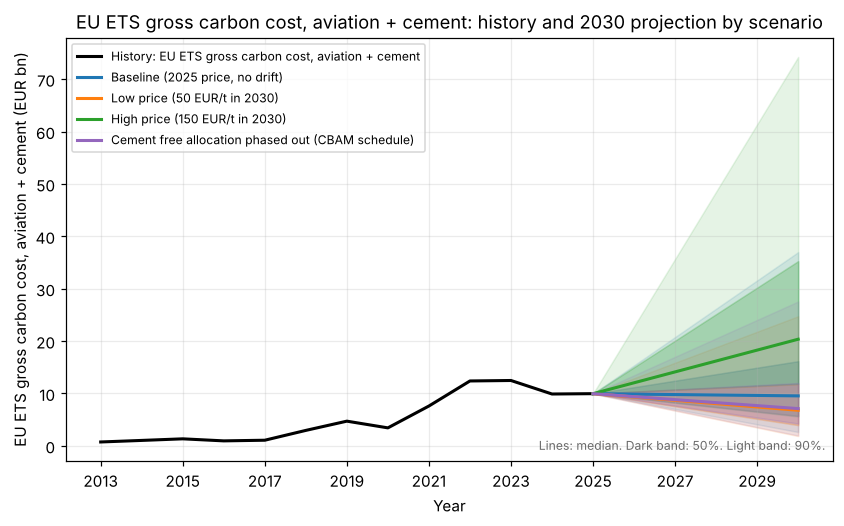

In [11]:
last_year, last_value = int(series["year"].iloc[-1]), series["value"].iloc[-1]
path_years = np.arange(last_year, TARGET_YEAR + 1)
frac = (path_years - last_year) / (TARGET_YEAR - last_year)   # 0 today -> 1 in the target year


def widen(q):
    # the band starts at today's value and widens linearly to the Part C/D quantile in 2030
    return last_value + (q - last_value) * frac


colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(series["year"], series["value"], color="black", lw=2, label=f"History: {NAME}")
for (name, d), c in zip(scenario_draws.items(), colors):
    p5, p25, p50, p75, p95 = np.percentile(d, [5, 25, 50, 75, 95])
    ax.fill_between(path_years, widen(p5), widen(p95), color=c, alpha=0.12)
    ax.fill_between(path_years, widen(p25), widen(p75), color=c, alpha=0.25)
    ax.plot(path_years, widen(p50), color=c, lw=2, label=name)
ax.set_xticks(np.arange(series["year"].min(), TARGET_YEAR + 1, 2))
ax.set_xlabel("Year")
ax.set_ylabel(f"{NAME} ({UNIT})")
ax.set_title(f"{NAME}: history and {TARGET_YEAR} projection by scenario")
ax.text(0.99, 0.02, "Lines: median. Dark band: 50%. Light band: 90%.", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color="dimgray")
ax.legend(fontsize=8, loc="upper left")
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

We project the 2030 gross EU ETS carbon cost of aviation and cement (before free allocation) under four scenarios. In the baseline the median is EUR 9.5 bn and the 90% interval is EUR 2.6-37.0 bn, so the cost is very likely to stay below EUR 37 bn. The carbon price drives the range: fixing it cuts the relative half-width from 180% to 8%. The largest scenario gap (EUR 13.6 bn, 50 versus 150 EUR/t) is smaller than any single-scenario interval. In the back-test, 0 of 5 held-out years fell inside the linear band and 5 of 5 inside the much wider log-linear band. One limitation: the price volatility rests on only 7 annual changes, and the upper end of the range depends on it.

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is **that we cannot rank companies on a single carbon-cost number: we stress each company's EBITDA at the high end of the price range (150 EUR/t and above) before flagging it as mispriced**."*